# Python 数据分析基础
**数据分析与机器学习 · 第 3–4 课时**

本节课先认识 Python 的数据类型、容器和基本语句，再用这些知识找出**超过阈值的位移读数**。最后用三个数据分析库处理同一组数据。

从上往下运行代码格。选中一个代码格后，点击运行按钮，也可以按 **Shift + Enter**。遇到练习，先预测结果或填写代码，再运行验证。

## 0. Python 版本与必要的库

第一格显示当前 Notebook 内核使用的 Python 版本。课堂基础语法部分可以直接用 Python 3 运行。

In [1]:
import sys

print(sys.version.split()[0])

3.14.6


In [2]:
!python --version

Python 3.12.16


## 1. 第一次运行 Notebook

依次运行下面两格。第一格给 `reading` 赋值，第二格将它与 `3.0` 比较并显示结果。

In [3]:
reading = 3.8

In [4]:
print(reading > 3.0)

True


**跟做。** 把第一格的 `3.8` 改成 `2.6`，先只运行第二格。然后重新运行第一格和第二格。两次结果有什么变化？修改代码后，对应单元格需要重新执行，内核中的变量才会更新。

## 2. 基本数据类型

变量名让我们以后还能找到一个值。`reading = 3.8` 把右边的值交给左边的名字 `reading`。再次给它赋值，接下来的代码就会读到新值。

**类型**说明一个值可以怎样使用。Python 可以对数值做减法，也可以对数值做比较。文本、数值和比较得到的真假值，各有适合的操作。用 `type(值)` 可以查看这个值的类型。

### 2.1 整数与浮点数

`4` 是整数（`int`），可以表示第几次测量。`3.8` 是浮点数（`float`），可以表示带小数的位移。注意 `3` 和 `3.0` 的数值相等，写出来的类型分别是整数和浮点数。运行下面一格，观察两种类型和一次减法的结果。

In [5]:
trial = 4
reading = 3.8
previous_reading = 2.6

print(type(trial))
print(type(reading))
print(f"Difference: {reading - previous_reading}")
print(f"Sum: {reading + previous_reading}")

<class 'int'>
<class 'float'>
Difference: 1.1999999999999997
Sum: 6.4


`round(..., 1)` 把结果保留到一位小数，方便对照读数。

### 2.2 布尔值

**布尔值**（`bool`）表示一个判断的真假，只有 `True` 和 `False` 两种取值。执行 `over_limit = 3.8 > 3.0` 时，Python 先算右边的比较，再把得到的 `True` 存到 `over_limit`。稍后 `if` 会根据这样的真假结果决定下一步。

In [6]:
over_limit = 3.8 > 3.0
print(over_limit)
print(type(over_limit))

True
<class 'bool'>


### 2.3 字符串

**字符串**（`str`）是一段文本，用引号括起来。`3.8` 写的是一个数，`"3.8"` 写的是由三个字符组成的文本。屏幕上它们可能看起来一样，可以用 `type()` 区分。

如果文本里的内容确实是一个数，可以用 `float("3.8")` 得到一个浮点数，再拿去比较。这在读表时常用，因为看起来像数字的内容有时是以文本存下来的。

In [7]:
reading_text = "3.8"
print(type(reading_text))

reading_value = float(reading_text)
print(type(reading_value))
print(reading_value > 3.0)

<class 'str'>
<class 'float'>
True


**练习 1｜辨认类型。** 先预测 `3`、`3.0` 和 `"3.0"` 分别是什么类型，再写三行代码验证。

In [8]:
# 在这里用 type() 和 print() 检查三个值。

## 3. 容器

一个名字也可以引用一组值，这样就可以把相关的数据一起保存。下面三种容器的区别可以从“怎样取值”和“怎样修改”来理解。

| 容器 | 适合保存 | 怎样取值 |
|---|---|---|
| 列表 `list` | 有顺序、还可能修改的一组读数 | 通过位置，例如 `readings[0]` |
| 元组 `tuple` | 位置含义固定的一组值，例如一个测点的两个坐标 | 通过位置，例如 `point[0]` |
| 字典 `dict` | 有字段名称的数据，例如一次测量的编号和读数 | 通过键，例如 `record["trial"]` |

### 3.1 列表（list）

方括号里的值用逗号隔开。Python 从 `0` 开始编号，三个值的位置分别是 `0`、`1`、`2`。`readings[0]` **读取**第一项，`readings[1] = 2.7` **替换**第二项。运行前先猜一猜哪一项会变。

In [9]:
readings = [1.2, 2.6, 3.0]
print(readings[0])

readings[1] = 2.7
print(readings)

1.2
[1.2, 2.7, 3.0]


### 3.2 元组（tuple）

`point = (2.0, 1.5)` 把一个测点的两个坐标放在一起。第一个位置代表横坐标，第二个位置代表纵坐标，仍然可以用 `[0]` 和 `[1]` 读取。元组创建后，它的各个位置不能通过下标赋值来替换。若测点位置变了，可以创建一个新的坐标元组。

In [10]:
point = (2.0, 1.5)
print(point[0])
print(point[1])

2.0
1.5


### 3.3 字典（dict）

一条测量记录同时有编号和位移，用字段名查找更容易读懂。在 `{"trial": 4, "reading_mm": 3.8}` 中，冒号左边是**键**，右边是该键对应的**值**。`record["reading_mm"]` 通过字段名取出读数。稍后创建 pandas 表格时，也会用字典的键来命名列。

In [11]:
record = {"trial": 4, "reading_mm": 3.8}
print(record["reading_mm"])

3.8


**练习 2｜从容器取值。** 分别取出列表 `readings` 的第三项、元组 `point` 的第二个坐标、字典 `record` 的测量编号。想一想每次该用位置还是键。

In [12]:
# 列表的第三项
# 元组的第二个坐标
# 字典中的测量编号

## 4. 条件判断与循环

### 4.1 用 if 判断一个值

`if` 让程序根据条件决定要不要做一件事。Python 先计算冒号前的条件 `reading > limit`。如果得到 `True`，就运行下面缩进的 `print(reading)`。如果得到 `False`，就跳过它。缩进表示哪些语句由这个判断控制，每一层用四个空格。

In [13]:
reading = 3.8
limit = 3.0

if reading > limit:
    print(reading)

3.8


**先预测。** 分别把 `reading` 改成 `2.6` 和 `3.0`。哪种情况会有输出？重新运行上面的代码验证。

### 4.2 用 for 遍历一组值

`for` 把同一段操作按顺序用于列表中的每个值。下面第一轮 `reading` 是 `1.2`，执行一次缩进里的 `print()`。第二轮它变成 `2.6`，再执行一次。遍历完最后一个值后，循环结束。这里用 `reading` 表示**当前一个读数**，用 `readings` 表示**整组读数**。

In [14]:
for reading in [1.2, 2.6, 3.0]:
    print(reading)

1.2
2.6
3.0


In [15]:
readings = [1.2, 2.6, 3.0]
for reading in readings:
    print(reading)

1.2
2.6
3.0


### 4.3 综合练习：筛选位移读数

下面是 PPT 中的五次模拟测量，单位为 mm。把 `pass` 替换为条件判断和输出语句，只输出**严格大于** `3.0` 的读数。

| 当前读数 | `reading > limit` | 这一轮怎么做 |
|---:|---|---|
| 3.0 | `False` | 跳过输出，继续下一轮 |
| 3.8 | `True` | 输出 3.8，再继续下一轮 |

写代码时，`if` 放在 `for` 里，`print()` 再缩进一层，放在 `if` 里。

In [16]:
readings = [1.2, 2.6, 3.0, 3.8, 4.1]
limit = 3.0

for reading in readings:
    # 在循环内补写 if 和 print()。
    pass

**课堂讲解。** 完成练习后，再运行这一格核对结果。把 `>` 改为 `>=` 会多输出哪条读数？

In [17]:
readings = [1.2, 2.6, 3.0, 3.8, 4.1]
limit = 3.0

for reading in readings:
    if reading > limit:
        print(reading)

3.8
4.1


## 5. 函数

### 5.1 为什么需要函数

假设位移仪在零位移时也会显示 `0.5 mm`。要判断是否超过 `3.0 mm`，每次都要先减去仪器的零点偏差，再比较修正后的位移。

In [ ]:
corrected_a = 4.5 - 0.5
print(corrected_a > 3.0)

corrected_b = 3.5 - 0.5
print(corrected_b > 3.0)

**先想一想。** 如果再来一个读数，哪些值会变？哪两步要重复做？

函数是一段可以用名字调用的代码。这里把“校正读数”和“判断是否超限”写在同一个函数里。以后遇到新读数，只要调用函数，把这次用到的值传进去。

### 5.2 定义函数与书写注释

`is_over_limit()` 用来判断**修正后的位移是否超限**。它接收三个值，单位都是 mm。

| 参数 | 含义 |
|---|---|
| `reading` | 仪器显示的原始读数 |
| `zero_offset` | 实际位移为零时，仪器显示的读数 |
| `limit` | 用来判断是否超限的阈值 |

函数返回布尔值。修正后的位移严格大于阈值时返回 `True`，其余情况返回 `False`。

`def` 开头的一行给出函数名和三个**形参**。冒号后缩进的语句是**函数体**。先运行定义格，让 Python 记下这个函数。调用时，Python 才会执行函数体。

In [ ]:
def is_over_limit(reading, zero_offset, limit):
    # 第一步：减去仪器的零点偏差，得到修正后的位移
    corrected = reading - zero_offset

    # 第二步：判断修正后的位移是否严格大于阈值，并返回判断结果
    return corrected > limit

函数里的两行 `#` 是**注释**。在代码中，写在字符串之外的 `#` 表示从这里到行末是给读代码的人看的说明，Python 执行时会跳过。独占一行的注释可以说明下一步做什么，行末注释可以标明该行的预期结果。

### 5.3 调用函数与修改规则

调用时传入的具体数值叫**实参**。以 `is_over_limit(4.5, 0.5, 3.0)` 为例，Python 按顺序把三个数交给形参。

| 步骤 | 这次调用发生了什么 |
|---|---|
| 接收实参 | `reading` 是 4.5，`zero_offset` 是 0.5，`limit` 是 3.0 |
| 校正读数 | `corrected = 4.5 - 0.5`，得到 4.0 mm |
| 返回结果 | `4.0 > 3.0` 得到 `True`，交回调用处 |

先预测第二次调用的结果，再运行。

In [ ]:
print(is_over_limit(4.5, 0.5, 3.0))  # 修正后为 4.0 mm，输出 True
print(is_over_limit(3.5, 0.5, 3.0))  # 修正后为 3.0 mm，输出 False

**试一试。**

1. 只改函数体里的注释文字，重新运行定义格和调用格。结果有变化吗？
2. 假设规则改成“达到或超过阈值”。在函数体里把 `>` 改为 `>=`，预测哪一次调用会改变，然后重新运行定义格和调用格。想一想，直接把计算写两遍时，要检查几处比较？
3. 完成后把比较符和对应注释恢复为“严格大于”，重新运行定义格，再继续下面的练习。

### 5.4 返回值与屏幕输出

`return` 把结果交给调用处，可以存进变量，也可以让 `if` 使用。`print()` 把结果显示在屏幕上。

下面第一种写法把判断结果存进 `result`，再打印。第二种写法在函数体中直接打印判断结果。这个函数没有写 `return`，调用结束后默认返回 `None`，因此 `shown` 里保存的是 `None`。

In [ ]:
result = is_over_limit(4.5, 0.5, 3.0)
print(result)

def show_over_limit(reading, zero_offset, limit):
    print(is_over_limit(reading, zero_offset, limit))

shown = show_over_limit(4.5, 0.5, 3.0)
print(shown)

### 5.5 综合练习：在循环里调用函数

仪器的零点偏差仍是 `0.5 mm`，阈值仍是 `3.0 mm`。用 `for` 逐条取出仪器读数，再用 `if` 检查 `is_over_limit()` 的返回值。如果返回 `True`，就打印这条**原始读数**，方便回到测量记录中查找。

用 `if` 和 `print()` 替换下面的 `pass`。先想一想，原始读数 `3.5 mm` 会不会打印。

In [ ]:
raw_readings = [2.0, 3.5, 4.5, 5.0]
zero_offset = 0.5
limit = 3.0

for reading in raw_readings:
    # 在 if 条件中调用 is_over_limit()。
    pass

**课堂讲解。** 检查输出是否只有原始读数 `4.5` 和 `5.0`。每轮循环只处理一条读数，校正和比较都由同一个函数完成。

In [ ]:
raw_readings = [2.0, 3.5, 4.5, 5.0]
zero_offset = 0.5
limit = 3.0

for reading in raw_readings:
    if is_over_limit(reading, zero_offset, limit):
        print(reading)

## 6. 类、对象与方法

可以把**类**理解为一类对象的定义，它规定这一类对象能保存什么数据、可以做哪些操作。pandas 的 `DataFrame` 类用来创建表格。`pd.DataFrame(data)` 根据字典创建出一张具体的表，这张表就是一个**对象**，变量 `df` 引用它。

`df.head()` 里的点号表示从 `df` 这个对象上取出一个操作，括号表示调用它。这样的操作叫**方法**。`head()` 会查看这张表的前几行。先把原始读数和阈值设回课堂使用的值，再建表。

In [24]:
import pandas as pd

trial_numbers = [1, 2, 3, 4, 5]
readings = [1.2, 2.6, 3.0, 3.8, 4.1]
limit = 3.0

data = {"trial": trial_numbers, "reading_mm": readings}
df = pd.DataFrame(data)
df.head()

,trial,reading_mm
0,1,1.2
1,2,2.6
2,3,3.0
3,4,3.8
4,5,4.1


**读代码。** 哪一行创建表格对象？哪一行调用它的方法？把 `df.head()` 改成 `df.head(2)`，先预测会出现几行，再运行。

NumPy、pandas 和 Matplotlib 用于后半段的数据分析演示。下面用一格检查当前环境能否找到它们。若提示缺少某个库，去掉安装行开头的 `#`，并只保留缺少的库名，再运行这一格。安装完成后，若仍无法导入，重启内核并从头运行。

`%pip` 将包安装到当前 IPython 内核使用的环境里。环境检查和安装格由教师演示，后续再讲 Python 代码的具体含义。

In [25]:
from importlib.util import find_spec

for package in ["numpy", "pandas", "matplotlib"]:
    status = "已找到" if find_spec(package) else "缺少"
    print(package, status)

# 缺少库时去掉下一行开头的 #，并保留需要安装的库名。
# %pip install numpy pandas matplotlib

numpy 已找到
pandas 已找到
matplotlib 已找到


## 7. NumPy、pandas 和 Matplotlib

这一节观察同一组数据怎样得到统计量、筛选表格和图形。

### 7.1 NumPy：计算均值

`import numpy as np` 导入 NumPy，并用 `np` 作为简写。`np.mean(readings)` 计算五个读数的平均值，结果为 **2.94 mm**。

In [26]:
import numpy as np

mean_reading = np.mean(readings)
print(round(float(mean_reading), 2), "mm")

2.94 mm


### 7.2 pandas：筛选表格

继续使用上一节创建的 `df`。根据位移列是否超过 `limit` 筛选整行。请把表格里的测量编号和读数对应起来。

In [27]:
df[df["reading_mm"] > limit]

,trial,reading_mm
3,4,3.8
4,5,4.1


### 7.3 Matplotlib：画读数和阈值线

横轴是测量编号，纵轴是位移。折线标出五次测量，虚线标出阈值。**读图题：**哪两次测量超过阈值？和表格筛选结果一致吗？

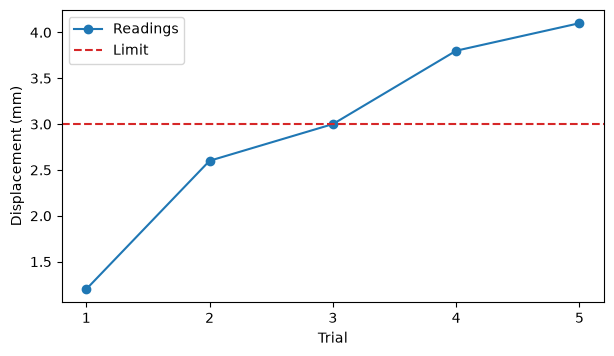

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3.8))
plt.plot(trial_numbers, readings, marker="o", label="Readings")
plt.axhline(limit, color="tab:red", linestyle="--", label="Limit")
plt.xticks(trial_numbers)
plt.xlabel("Trial")
plt.ylabel("Displacement (mm)")
plt.legend()
plt.show()

## 8. 课后作业

**必做。** 用下面的新数据，自己定义一个返回布尔值的判断函数，再配合 `for` 和 `if` 输出所有超过阈值的读数。检查恰好等于阈值的读数有没有被输出。

In [29]:
homework_readings = [2.3, 3.5, 3.9, 4.4, 3.2]
homework_limit = 3.5

# 在这里定义函数，并遍历 homework_readings 进行筛选。

**体验。** 在下方独立运行三个库的示例，核对表格和图形。把下面的“我的回答”改成一句话，写出图上哪些读数超过了阈值。

**我的回答：** ……

保存并提交 `.ipynb` 文件。提交前重启内核，从头运行所有代码格一次。

Mean: 3.46 mm


,trial,reading_mm
2,3,3.9
3,4,4.4


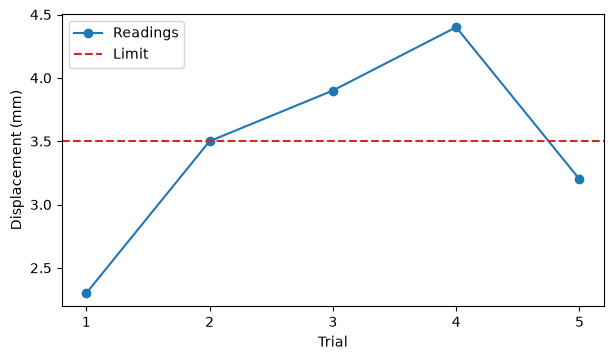

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

homework_trials = list(range(1, len(homework_readings) + 1))
print("Mean:", round(float(np.mean(homework_readings)), 2), "mm")

homework_df = pd.DataFrame({
    "trial": homework_trials,
    "reading_mm": homework_readings,
})
display(homework_df[homework_df["reading_mm"] > homework_limit])

plt.figure(figsize=(7, 3.8))
plt.plot(homework_trials, homework_readings, marker="o", label="Readings")
plt.axhline(homework_limit, color="tab:red", linestyle="--", label="Limit")
plt.xticks(homework_trials)
plt.xlabel("Trial")
plt.ylabel("Displacement (mm)")
plt.legend()
plt.show()

---

编排参考：项目中的 `python-colab.ipynb`（CS231n Python/Numpy Review Tutorial）与原和鲸课堂版。版本检查及安装命令参见 [IPython 的 %pip 文档](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-pip)。